# Proyecto 7: Regresión del límite de crédito (`LIMIT_BAL`)

**Equipo:** Franco [F] y Olena [L]
**Dataset:** Default of Credit Card Clients (UCI). 30.000 clientes de un banco de Taiwán, de abril a septiembre de 2005. Importes en NT$.

## 0. Introducción [F]

**Objetivo:** estimar el límite de crédito (`LIMIT_BAL`) de un cliente a partir de su perfil y de su historial de los últimos 6 meses.

**Caso de uso:** revisión del límite de clientes existentes, de los que el banco ya conoce el historial de pagos.

**Por qué `LIMIT_BAL`:**
- Es continua y el resultado es directamente una propuesta de límite.
- `default.payment.next.month` es binaria (clasificación) y es un dato del mes siguiente.
- `BILL_AMT1` depende mucho de la factura del mes anterior: predecirla sería casi copiarla.

**Índice**

0. Introducción [F]
1. Carga y calidad de los datos [F]
2. Variable objetivo `LIMIT_BAL` [F]
3. Perfil del cliente (`SEX`, `EDUCATION`, `MARRIAGE`, `AGE`) [F]
4. Historial de pagos (`PAY_*`, `BILL_AMT*`, `PAY_AMT*`) [L]
5. Correlaciones [L]
6. Conclusiones del EDA [F]
7. Limpieza y preprocesamiento [F]
8. Modelo base [F]
9. Ensembles: Random Forest y Gradient Boosting [F]
10. Ensembles: XGBoost [L]
11. Optuna y modelo final [F]
12. Informe de métricas y conclusiones finales [F]

## 1. Carga y calidad de los datos [F]

In [76]:
# Librerías de análisis, visualización y modelado
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline

# Funciones propias de preprocesamiento (carpeta src/, un nivel por encima de notebooks/)
sys.path.append("..")
from src.preprocesamiento import (
    COLS_BILL, COLS_PAY_AMT, agrupar_codigos, crear_preprocesador, log_con_signo,
)

# Configuración visual de los gráficos (común a todo el notebook)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Cargamos el dataset desde la carpeta data/ (única carga de datos del notebook)
df = pd.read_csv("../data/UCI_Credit_Card.csv")

# Comprobamos dimensiones, nulos y duplicados
print(f"Dimensiones del dataset (filas, columnas): {df.shape}")
print(f"Total de valores nulos: {df.isna().sum().sum()}")
print(f"Filas duplicadas: {df.duplicated().sum()}")

# ID es distinto en cada fila, así que puede esconder filas repetidas: repetimos la comprobación sin él
print(f"Filas duplicadas sin contar ID: {df.drop(columns='ID').duplicated().sum()}")

df.head()

Dimensiones del dataset (filas, columnas): (30000, 25)
Total de valores nulos: 0
Filas duplicadas: 0
Filas duplicadas sin contar ID: 35


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [77]:
# Tipos de dato de cada columna: todas son numéricas, incluidas las categóricas codificadas
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

In [78]:
# Resumen estadístico de todas las columnas (traspuesto para leerlo mejor)
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.5,8660.4,1.0,7500.8,15000.5,22500.2,30000.0
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_0,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0


In [79]:
# Inspeccionamos las filas repetidas sin ID (todas las copias) para entender qué son
cols_sin_id = df.columns.drop("ID")
duplicados_sin_id = df[df[cols_sin_id].duplicated(keep=False)]
cols_bill_dup = [f"BILL_AMT{i}" for i in range(1, 7)]
facturas_a_cero = (duplicados_sin_id[cols_bill_dup].abs().sum(axis=1) == 0).mean()

print(f"Filas implicadas (todas las copias): {len(duplicados_sin_id)}")
print(f"Porcentaje de esas filas con las 6 facturas a 0: {facturas_a_cero:.0%}")
duplicados_sin_id.sort_values(list(cols_sin_id)).head(6)

Filas implicadas (todas las copias): 70
Porcentaje de esas filas con las 6 facturas a 0: 86%


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
12430,12431,20000.0,1,2,2,24,2,2,4,4,...,1650.0,1650.0,1650.0,0.0,0.0,0.0,0.0,0.0,0.0,1
14294,14295,20000.0,1,2,2,24,2,2,4,4,...,1650.0,1650.0,1650.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1759,1760,50000.0,1,2,2,26,1,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
10250,10251,50000.0,1,2,2,26,1,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
7170,7171,50000.0,2,1,2,23,1,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
17032,17033,50000.0,2,1,2,23,1,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


### Conclusiones de la sección 1

- 30.000 filas y 25 columnas, todas numéricas y sin nulos.
- `ID` es un identificador: lo eliminamos en la sección 7.
- Sin `ID` hay 35 filas repetidas, casi todas cuentas sin actividad (las 6 facturas a 0). Las tratamos en la sección 7.
- `EDUCATION` llega a 6 y `MARRIAGE` empieza en 0: códigos no documentados (sección 3).

## 2. Variable objetivo: `LIMIT_BAL` [F]

In [80]:
limite = df["LIMIT_BAL"]

# Resumen numérico del límite de crédito
print(limite.describe().round(0))
print(f"\nAsimetría (skew): {limite.skew():.2f}")
print(f"Valores distintos: {limite.nunique()}")

# Límites más frecuentes: el banco asigna límites por escalones
print("\nLos 10 límites más frecuentes:")
print(limite.value_counts().head(10))

# Comprobamos qué valores no son múltiplos de 10.000
limite_no_multiplo = limite[limite % 10_000 != 0]
print(f"\nFilas con límite no múltiplo de 10.000: {len(limite_no_multiplo)}")
print(limite_no_multiplo.value_counts())

# Valores extremos según la regla del rango intercuartílico (IQR)
q1_limite, q3_limite = limite.quantile([0.25, 0.75])
umbral_limite = q3_limite + 1.5 * (q3_limite - q1_limite)
print(f"\nUmbral superior IQR: {umbral_limite:,.0f} NT$")
print(f"Clientes por encima del umbral: {(limite > umbral_limite).sum()}")

count      30000.0
mean      167484.0
std       129748.0
min        10000.0
25%        50000.0
50%       140000.0
75%       240000.0
max      1000000.0
Name: LIMIT_BAL, dtype: float64

Asimetría (skew): 0.99
Valores distintos: 81

Los 10 límites más frecuentes:
LIMIT_BAL
50000.0     3365
20000.0     1976
30000.0     1610
80000.0     1567
200000.0    1528
150000.0    1110
100000.0    1048
180000.0     995
360000.0     881
60000.0      825
Name: count, dtype: int64

Filas con límite no múltiplo de 10.000: 3
LIMIT_BAL
16000.0     2
327680.0    1
Name: count, dtype: int64

Umbral superior IQR: 525,000 NT$
Clientes por encima del umbral: 167


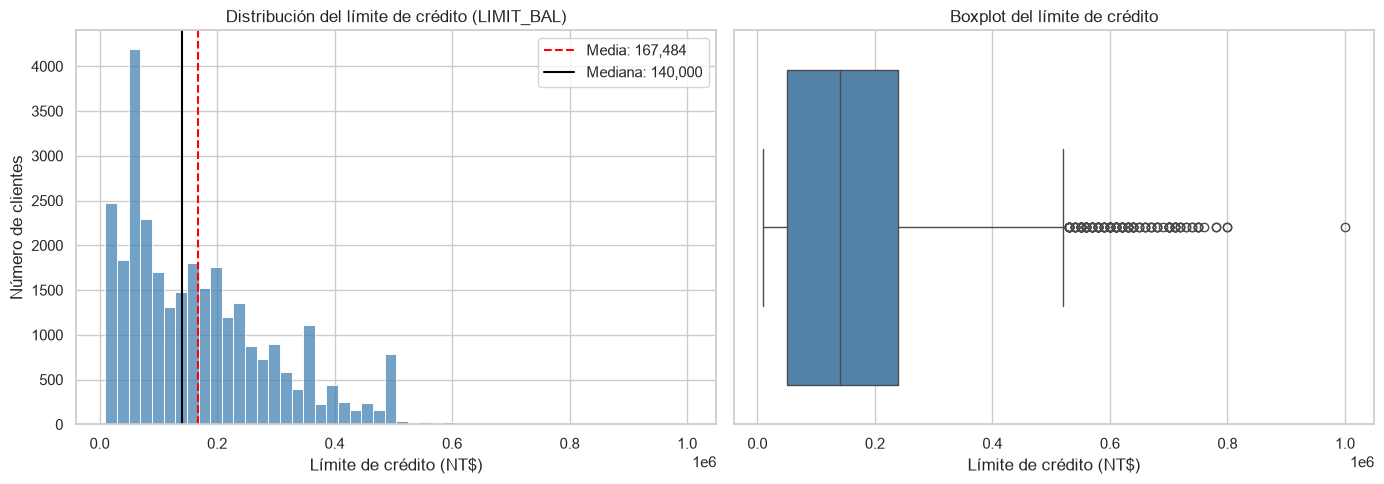

In [81]:
# Gráfico: distribución del límite (histograma) y valores extremos (boxplot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(limite, bins=50, ax=axes[0], color="steelblue")
axes[0].axvline(limite.mean(), color="red", linestyle="--", label=f"Media: {limite.mean():,.0f}")
axes[0].axvline(limite.median(), color="black", label=f"Mediana: {limite.median():,.0f}")
axes[0].set_title("Distribución del límite de crédito (LIMIT_BAL)")
axes[0].set_xlabel("Límite de crédito (NT$)")
axes[0].set_ylabel("Número de clientes")
axes[0].legend()

sns.boxplot(x=limite, ax=axes[1], color="steelblue")
axes[1].set_title("Boxplot del límite de crédito")
axes[1].set_xlabel("Límite de crédito (NT$)")

plt.tight_layout()
plt.show()

### Conclusiones de la sección 2

- De 10.000 a 1.000.000 NT$. Mediana 140.000, media 167.484 y asimetría 0,99: cola a la derecha.
- 81 valores distintos, casi todos múltiplos de 10.000 (excepciones: 16.000 en 2 filas y 327.680 en 1). La tratamos como continua.
- 167 clientes por encima del umbral IQR (525.000 NT$). Los mantenemos: son límites reales.
- De momento no transformamos el target. Lo revisaremos con los residuos en la sección 8.
- Por la cola a la derecha, informaremos el MAE además del RMSE.

## 3. Perfil del cliente: `SEX`, `EDUCATION`, `MARRIAGE` y `AGE` [F]

### 3.1 Variables categóricas

Códigos según la documentación del dataset:
- `SEX`: 1 = hombre, 2 = mujer.
- `EDUCATION`: 1 = posgrado, 2 = universidad, 3 = secundaria, 4 = otros.
- `MARRIAGE`: 1 = casado, 2 = soltero, 3 = otros.

In [82]:
cols_perfil_cat = ["SEX", "EDUCATION", "MARRIAGE"]
codigos_documentados = {"SEX": [1, 2], "EDUCATION": [1, 2, 3, 4], "MARRIAGE": [1, 2, 3]}

for col in cols_perfil_cat:
    resumen_cat = (
        df.groupby(col)["LIMIT_BAL"]
        .agg(clientes="count", limite_medio="mean", limite_mediano="median")
        .round(0)
    )
    resumen_cat["documentado"] = resumen_cat.index.isin(codigos_documentados[col])
    filas_no_documentadas = resumen_cat.loc[~resumen_cat["documentado"], "clientes"].sum()
    print(f"\n{col}: {filas_no_documentadas} filas con código no documentado")
    display(resumen_cat)


SEX: 0 filas con código no documentado


,clientes,limite_medio,limite_mediano,documentado
SEX,,,,
1,11888,163520.0,130000.0,True
2,18112,170086.0,150000.0,True



EDUCATION: 345 filas con código no documentado


,clientes,limite_medio,limite_mediano,documentado
EDUCATION,,,,
0,14,217143.0,215000.0,False
1,10585,212956.0,200000.0,True
2,14030,147062.0,110000.0,True
3,4917,126550.0,80000.0,True
4,123,220894.0,200000.0,True
5,280,168164.0,150000.0,False
6,51,148235.0,100000.0,False



MARRIAGE: 54 filas con código no documentado


,clientes,limite_medio,limite_mediano,documentado
MARRIAGE,,,,
0,54,132963.0,115000.0,False
1,13659,182201.0,160000.0,True
2,15964,156414.0,130000.0,True
3,323,98080.0,60000.0,True


In [ ]:
# Gráfico: límite de crédito por categoría
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, cols_perfil_cat):
    sns.boxplot(data=df, x=col, y="LIMIT_BAL", ax=ax, color="lightsteelblue")
    ax.set_title(f"Límite de crédito según {col}")
    ax.set_xlabel(f"Código de {col}")
    ax.set_ylabel("Límite de crédito (NT$)")

plt.tight_layout()
plt.show()

### 3.2 Edad (`AGE`)

In [ ]:
edad = df["AGE"]

print(edad.describe().round(1))
print(f"\nCorrelación lineal (Pearson) entre AGE y LIMIT_BAL: {edad.corr(df['LIMIT_BAL']):.3f}")

# Agrupamos la edad en tramos para ver si la relación es no lineal
tramos_edad = pd.cut(edad, bins=[20, 25, 30, 35, 40, 45, 50, 60, 80])
resumen_edad = (
    df.groupby(tramos_edad, observed=True)["LIMIT_BAL"]
    .agg(clientes="count", limite_mediano="median")
)
display(resumen_edad)

In [ ]:
# Gráfico: distribución de la edad y límite de crédito por tramo de edad
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(edad, bins=30, ax=axes[0], color="seagreen")
axes[0].set_title("Distribución de la edad (AGE)")
axes[0].set_xlabel("Edad (años)")
axes[0].set_ylabel("Número de clientes")

sns.boxplot(x=tramos_edad.astype(str), y=df["LIMIT_BAL"], ax=axes[1], color="mediumseagreen",
            order=[str(t) for t in tramos_edad.cat.categories])
axes[1].set_title("Límite de crédito según tramo de edad")
axes[1].set_xlabel("Tramo de edad (años)")
axes[1].set_ylabel("Límite de crédito (NT$)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Conclusiones de la sección 3

- **Códigos no documentados:** `EDUCATION` 0 (14 filas), 5 (280) y 6 (51); `MARRIAGE` 0 (54). Los agrupamos en "otros" (4 y 3).
- **`EDUCATION`:** mediana de 200.000 NT$ en posgrado, 110.000 en universidad y 80.000 en secundaria.
- **`MARRIAGE`:** mediana de 160.000 en casados y 130.000 en solteros. Los casados son mayores (mediana de edad 39 frente a 29), así que parte de la diferencia puede venir de la edad.
- **`SEX`:** mediana de 130.000 en hombres y 150.000 en mujeres. Variable sensible: decidimos su uso en la sección 7.
- **`AGE`:** de 21 a 79 años. Correlación lineal baja (0,145), pero por tramos forma una U invertida: 50.000 entre 21 y 25 años, 180.000 entre 30 y 40 y 110.000 entre 50 y 60.

## 4. Historial de pagos: `PAY_*`, `BILL_AMT*` y `PAY_AMT*` [L]

Analizamos el comportamiento de los clientes durante los 6 meses previos (abril a septiembre de 2005) y su relación con el límite de crédito, y buscamos problemas de calidad o de estructura (asimetría, valores negativos, multicolinealidad) para el preprocesamiento.

In [ ]:
# Columnas del historial de 6 meses y el target (se usan en las secciones 4 y 5)
cols_historial = (
    ["LIMIT_BAL"]
    + [c for c in df.columns if c.startswith(("PAY_", "BILL_AMT", "PAY_AMT"))]
)
df[cols_historial].head()

### 4.1 Estado de pago mensual (`PAY_0`, `PAY_2` a `PAY_6`)
Analizamos la distribución de los códigos de estado de pago y cómo varía el límite de crédito medio (`LIMIT_BAL`) según los meses de retraso.

- **Nota sobre nombres:** `PAY_0` corresponde a septiembre de 2005 (mes 1); no existe columna `PAY_1`. En el preprocesamiento se renombrará `PAY_0` -> `PAY_1`.
- **Interpretación de códigos:** `-2` = sin consumo, `-1` = pagado completo al día, `0` = uso de crédito rotativo (pago mínimo al día), `1` a `8` = meses de retraso acumulado.

In [ ]:
# Columnas de estado de pago (de septiembre a abril de 2005)
cols_pay = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

# Tabla de frecuencias de cada código en los 6 meses
conteos_pay = df[cols_pay].apply(lambda s: s.value_counts()).fillna(0).astype(int)
print("Conteo de clientes por código de estado de pago en cada mes:")
display(conteos_pay)

# Relación entre PAY_0 (septiembre) y el límite de crédito (LIMIT_BAL)
resumen_pay0 = (
    df.groupby("PAY_0")["LIMIT_BAL"]
    .agg(clientes="count", limite_medio="mean", limite_mediano="median")
    .round(0)
)
print("\nLímite de crédito según el estado de pago en septiembre (PAY_0):")
display(resumen_pay0)

In [ ]:
# Gráfico: conteo de clientes y límite medio según estado de pago en septiembre (PAY_0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1) Distribución de clientes por valor de PAY_0
sns.countplot(data=df, x="PAY_0", ax=axes[0], color="steelblue")
axes[0].set_title("Número de clientes según estado de pago (PAY_0 - Septiembre)")
axes[0].set_xlabel("Código de estado de pago (PAY_0)")
axes[0].set_ylabel("Número de clientes")

# 2) Límite de crédito medio por valor de PAY_0
sns.barplot(data=df, x="PAY_0", y="LIMIT_BAL", estimator=np.mean, errorbar=None, ax=axes[1], color="teal")
axes[1].set_title("Límite de crédito medio (LIMIT_BAL) según PAY_0")
axes[1].set_xlabel("Código de estado de pago (PAY_0)")
axes[1].set_ylabel("Límite de crédito medio (NT$)")

plt.tight_layout()
plt.show()

### 4.2 Facturas (`BILL_AMT1..6`) y pagos (`PAY_AMT1..6`): asimetría y facturas negativas
Inspeccionamos las estadísticas descriptivas (mínimo, mediana, media, máximo y asimetría `skew`), el número de facturas negativas (saldo a favor del cliente) y comparamos la distribución en escala original frente a escala logarítmica.

In [ ]:
cols_bill = [f"BILL_AMT{i}" for i in range(1, 7)]
cols_pay_amt = [f"PAY_AMT{i}" for i in range(1, 7)]

print("Estadísticas de facturas mensuales (BILL_AMT1..6):")
display(df[cols_bill].agg(["min", "median", "mean", "max", "skew"]).round(1))

print("\nNúmero de facturas negativas (saldo a favor) por mes:")
print((df[cols_bill] < 0).sum())

print("\nEstadísticas de pagos mensuales (PAY_AMT1..6):")
display(df[cols_pay_amt].agg(["min", "median", "mean", "max", "skew"]).round(1))

In [ ]:
# Comparación visual en escala normal vs logarítmica para BILL_AMT1 y PAY_AMT1
# Para BILL_AMT1 usamos log con signo porque existen facturas negativas (saldo a favor)
bill1_log_signo = np.sign(df["BILL_AMT1"]) * np.log1p(np.abs(df["BILL_AMT1"]))
pay1_log = np.log1p(df["PAY_AMT1"])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# BILL_AMT1 original vs log con signo
sns.histplot(df["BILL_AMT1"], bins=50, ax=axes[0, 0], color="royalblue")
axes[0, 0].set_title("BILL_AMT1 en escala original (asimetría = 2,7)")
axes[0, 0].set_xlabel("Importe de factura en septiembre (NT$)")

sns.histplot(bill1_log_signo, bins=50, ax=axes[0, 1], color="royalblue")
axes[0, 1].set_title("BILL_AMT1 con logaritmo con signo: sign(x) * log1p(|x|)")
axes[0, 1].set_xlabel("BILL_AMT1 transformado")

# PAY_AMT1 original vs log1p
sns.histplot(df["PAY_AMT1"], bins=50, ax=axes[1, 0], color="darkorange")
axes[1, 0].set_title("PAY_AMT1 en escala original (asimetría = 14,7)")
axes[1, 0].set_xlabel("Importe pagado en septiembre (NT$)")

sns.histplot(pay1_log, bins=50, ax=axes[1, 1], color="darkorange")
axes[1, 1].set_title("PAY_AMT1 con transformación log1p(x)")
axes[1, 1].set_xlabel("PAY_AMT1 transformado")

plt.tight_layout()
plt.show()

## 5. Correlaciones con `LIMIT_BAL` y multicolinealidad en el historial [L]
Calculamos la matriz de correlación de Pearson entre `LIMIT_BAL` y las 18 variables del historial (`PAY_*`, `BILL_AMT*`, `PAY_AMT*`) para evaluar qué variables tienen mayor relación lineal con el límite y detectar bloques de variables redundantes (**multicolinealidad**).

In [ ]:
# Matriz de correlación entre LIMIT_BAL y las variables de historial
corr_matrix = df[cols_historial].corr()

# Ordenamos las correlaciones respecto a LIMIT_BAL
print("Correlación con el límite de crédito (LIMIT_BAL):")
print(corr_matrix["LIMIT_BAL"].drop("LIMIT_BAL").sort_values(ascending=False).round(2))

# Mapa de calor (heatmap)
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Mapa de calor de correlaciones: LIMIT_BAL e historial de 6 meses")
plt.tight_layout()
plt.show()

### Conclusiones de las secciones 4 y 5

1. **Sin valores nulos ni filas duplicadas:** Las 30.000 filas están completas, por lo que no se requiere imputación de nulos.
2. **Desfase de nombres en `PAY_*`:** La columna de estado de pago de septiembre (mes 1) se llama `PAY_0` y no existe `PAY_1`. **Acción para preprocesamiento:** renombrar `PAY_0` a `PAY_1` para que coincida con `BILL_AMT1` y `PAY_AMT1`.
3. **Relación clara entre retrasos (`PAY_*`) y `LIMIT_BAL`:** Son variables ordinales con correlación negativa respecto al límite (`-0,24` a `-0,30`). Los clientes que pagan el total (`-1`) o no consumen (`-2`) tienen límites medianos de 200.000 a 230.000 NT$, frente a 80.000 NT$ con 2 meses de retraso y 50.000 NT$ con 3 meses de retraso. **Acción:** mantenerlas como numéricas ordinales.
4. **Facturas negativas en `BILL_AMT1..6`:** Entre 590 y 688 clientes por mes presentan importes negativos (hasta `-339.603 NT$`). Representan **saldo a favor del cliente**, no errores de captura. **Acción:** conservar esas filas.
5. **Fuerte asimetría positiva en importes (`BILL_AMT*` y `PAY_AMT*`):** La asimetría (`skew`) ronda `2,7 - 3,1` en facturas y llega a `10,6 - 30,5` en pagos. **Acción:** aplicar `log1p(x)` en `PAY_AMT*` y logaritmo con signo `sign(x) * log1p(abs(x))` en `BILL_AMT*`.
6. **Multicolinealidad alta en `BILL_AMT1..6` y techo de señal lineal:** Las seis facturas mensuales están muy correlacionadas entre sí (`0,80` a `0,95`), lo que indica que la deuda se arrastra de un mes a otro. La correlación individual máxima con `LIMIT_BAL` es moderada (`0,30` en `BILL_AMT5` y `-0,30` en `PAY_2`), lo que explica por qué un modelo lineal tendrá un techo de $R^2$ moderado y por qué necesitaremos modelos de árboles (*ensembles*) y regularización (`Ridge`) para aprovechar relaciones no lineales y manejar la multicolinealidad.

## 6. Conclusiones del EDA [F]

| Problema | Evidencia | Qué haremos | Sección |
|---|---|---|---|
| `ID` no aporta información | Identificador distinto por fila | Eliminar la columna | 1 |
| Filas repetidas sin `ID` | 35, casi todas cuentas sin actividad | Eliminarlas antes de separar train y test | 1 |
| Target asimétrico con valores extremos | Asimetría 0,99; 167 clientes por encima de 525.000 NT$ | Conservar todos los valores; informar MAE además de RMSE | 2 |
| Códigos no documentados en `EDUCATION` | 0, 5 y 6 en 345 filas | Agrupar en 4 ("otros") | 3 |
| Códigos no documentados en `MARRIAGE` | 0 en 54 filas | Agrupar en 3 ("otros") | 3 |
| `SEX` es una variable sensible | Mediana 130.000 frente a 150.000 | Excluirla del modelo y medir cuánto aporta | 3 |
| Relación no lineal con la edad | U invertida por tramos, correlación 0,145 | Mantener `AGE` numérica | 3 |
| Nombre `PAY_0` desfasado | No existe `PAY_1` | Renombrar `PAY_0` a `PAY_1` | 4 |
| `PAY_*` son ordinales | Más retraso, menor límite | Mantener como numéricas | 4 |
| Facturas negativas en `BILL_AMT*` | 590 a 688 por mes, saldo a favor | Conservar las filas; logaritmo con signo | 4 |
| Fuerte asimetría en importes | Asimetría de 2,7 a 3,1 (facturas) y de 10,6 a 30,5 (pagos) | `log1p` en `PAY_AMT*`; logaritmo con signo en `BILL_AMT*` | 4 |
| Multicolinealidad en `BILL_AMT1..6` | Correlación de 0,80 a 0,95 entre meses | Regularización (`Ridge`) y modelos de árboles | 5 |

**Data leakage:**
- Excluimos `default.payment.next.month`: es un dato del mes siguiente.
- No creamos variables a partir de `LIMIT_BAL` (por ejemplo, factura / límite).
- Un $R^2$ de test muy por encima de lo que hacen esperar estas correlaciones se revisa como posible leakage.

**Problemas de calidad principales:**
1. Códigos categóricos no documentados (`EDUCATION` y `MARRIAGE`).
2. Fuerte asimetría en los importes y en el target.
3. Variables muy redundantes entre sí (las seis facturas mensuales).

## 7. Limpieza y preprocesamiento [F]

Orden para evitar data leakage:
1. Limpieza fija, que no aprende de los datos: sobre todo el dataset.
2. Separación en train y test.
3. Pipeline de preprocesamiento: se ajusta solo con train.

### 7.1 Limpieza fija

- Eliminamos `ID` (identificador) y `default.payment.next.month` (dato del mes siguiente).
- Renombramos `PAY_0` a `PAY_1`, como `BILL_AMT1` y `PAY_AMT1`.
- Trabajamos sobre `df_modelo`; `df` queda intacto para el EDA.

In [ ]:
# Copia del dataset para el modelado: df se queda intacto para el EDA
df_modelo = df.copy()

# Quitamos el identificador y la variable del mes siguiente (leakage)
df_modelo = df_modelo.drop(columns=["ID", "default.payment.next.month"])

# Unificamos la numeración de los meses: PAY_0 pasa a ser PAY_1 (septiembre)
df_modelo = df_modelo.rename(columns={"PAY_0": "PAY_1"})

print(f"Dimensiones tras la limpieza fija: {df_modelo.shape}")
print(f"Columnas: {list(df_modelo.columns)}")

### 7.2 Filas repetidas

Las eliminamos antes del split para que la misma fila no esté en train y en test. Las buscamos en las columnas que verá el modelo, sin `SEX`. Mantenemos `SEX` en `df_modelo` para medir en la sección 8 cuánto aporta.

In [ ]:
# Columnas que verá el modelo: todas las de df_modelo menos SEX
cols_duplicados = df_modelo.columns.drop("SEX")

n_repetidas = df_modelo.duplicated(subset=cols_duplicados).sum()
print(f"Filas repetidas en las columnas del modelo: {n_repetidas}")

# Conservamos la primera aparición de cada fila y renumeramos el índice
df_modelo = df_modelo.drop_duplicates(subset=cols_duplicados).reset_index(drop=True)
print(f"Dimensiones tras eliminar repetidas: {df_modelo.shape}")

### 7.3 Separación en train y test

80% train y 20% test, con `random_state=42` para que el reparto sea siempre el mismo. El test no se usa hasta la evaluación final.

In [ ]:
# Variable objetivo (y) y variables de entrada (X)
y = df_modelo["LIMIT_BAL"]
X = df_modelo.drop(columns="LIMIT_BAL")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Train: {X_train.shape[0]} filas, {X_train.shape[1]} columnas")
print(f"Test:  {X_test.shape[0]} filas, {X_test.shape[1]} columnas")

# El límite debe tener una distribución parecida en las dos partes
print(f"\nMediana de LIMIT_BAL en train: {y_train.median():,.0f}".replace(",", "."))
print(f"Mediana de LIMIT_BAL en test:  {y_test.median():,.0f}".replace(",", "."))

### 7.4 Funciones de preprocesamiento

Están en `src/preprocesamiento.py` para que la app use las mismas. Las comprobamos sobre `X_train`.

In [ ]:
# Códigos de EDUCATION y MARRIAGE antes y después de agrupar
X_agrupado = agrupar_codigos(X_train)

for col in ["EDUCATION", "MARRIAGE"]:
    print(f"{col} antes:   {sorted(X_train[col].unique().tolist())}")
    print(f"{col} después: {sorted(X_agrupado[col].unique().tolist())}")

In [ ]:
# Asimetría de los importes antes y después del logaritmo
importes_log = pd.concat(
    [log_con_signo(X_train[COLS_BILL]), np.log1p(X_train[COLS_PAY_AMT])], axis=1
)

asimetria = pd.DataFrame({
    "original": X_train[COLS_BILL + COLS_PAY_AMT].skew(),
    "con logaritmo": importes_log.skew(),
}).round(2)
asimetria

### 7.5 Pipeline de preprocesamiento

`crear_preprocesador` (en `src/preprocesamiento.py`) aplica a cada grupo de columnas su tratamiento:

| Columnas | Tratamiento |
|---|---|
| `EDUCATION`, `MARRIAGE` | Agrupar códigos no documentados y one-hot |
| `BILL_AMT1..6` | Escalado (logaritmo con signo si `usar_log=True`) |
| `PAY_AMT1..6` | Escalado (`log1p` si `usar_log=True`) |
| `AGE`, `PAY_1..6` | Escalado |
| `SEX` | Fuera del modelo (`incluir_sex=True` para medir cuánto aporta) |

Se ajusta solo con train. Los logaritmos quedan desactivados por defecto (ver sección 8.2).

In [ ]:
preprocesador = crear_preprocesador()

# fit_transform: aprende de train (categorías, medias y desviaciones) y lo transforma
X_train_prep = pd.DataFrame(
    preprocesador.fit_transform(X_train),
    columns=preprocesador.get_feature_names_out(),
    index=X_train.index,
)

print(f"Antes:   {X_train.shape}")
print(f"Después: {X_train_prep.shape}")

In [ ]:
# Escaladas: media 0 y desviación 1. One-hot: la media es la proporción de clientes de cada categoría
X_train_prep.describe().T[["mean", "std"]].round(2)

## 8. Modelo base [F]

Validación cruzada de 5 folds sobre train; el test sigue sin usarse.

Overfitting = (RMSE validación - RMSE train) / RMSE train x 100. Objetivo: menos del 5%.

In [ ]:
# 5 folds con el mismo reparto para todos los modelos
cv = KFold(n_splits=5, shuffle=True, random_state=42)
metricas = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}


def evaluar(nombre, modelo, **opciones_prep):
    """Validación cruzada del pipeline completo (preprocesado + modelo). Devuelve las métricas medias."""
    pipeline = Pipeline([("prep", crear_preprocesador(**opciones_prep)), ("modelo", modelo)])
    res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=metricas, return_train_score=True)

    # cross_validate llama "test" al fold de validación; scikit-learn da los errores en negativo
    rmse_train = -res["train_rmse"].mean()
    rmse_val = -res["test_rmse"].mean()
    return {
        "modelo": nombre,
        "RMSE train": round(rmse_train),
        "RMSE validación": round(rmse_val),
        "MAE validación": round(-res["test_mae"].mean()),
        "R2 train": round(res["train_r2"].mean(), 3),
        "R2 validación": round(res["test_r2"].mean(), 3),
        "Overfitting (%)": round((rmse_val - rmse_train) / rmse_train * 100, 2),
    }

### 8.1 Dummy, regresión lineal y Ridge

In [ ]:
resultados_base = pd.DataFrame([
    evaluar("Dummy (media)", DummyRegressor()),
    evaluar("Lineal", LinearRegression()),
    evaluar("Ridge alpha=1", Ridge(alpha=1)),
    evaluar("Ridge alpha=100", Ridge(alpha=100)),
]).set_index("modelo")
resultados_base

### 8.2 Logaritmo en los importes

In [ ]:
resultados_log = pd.DataFrame([
    evaluar("Lineal sin logaritmo", LinearRegression()),
    evaluar("Lineal con logaritmo", LinearRegression(), usar_log=True),
]).set_index("modelo")
resultados_log

### 8.3 Variable `SEX`

In [ ]:
resultados_sex = pd.DataFrame([
    evaluar("Lineal sin SEX", LinearRegression()),
    evaluar("Lineal con SEX", LinearRegression(), incluir_sex=True),
]).set_index("modelo")
resultados_sex

### 8.4 Residuos del modelo lineal

Residuo = límite real - límite predicho. Usamos predicciones de validación cruzada: cada cliente se predice con un modelo que no lo vio al entrenar.

In [ ]:
pipeline_lineal = Pipeline([("prep", crear_preprocesador()), ("modelo", LinearRegression())])

pred_val = cross_val_predict(pipeline_lineal, X_train, y_train, cv=cv)
residuos = y_train - pred_val

print(f"Predicciones negativas (límite imposible): {(pred_val < 0).sum()}")
print(f"Residuo medio: {residuos.mean():,.0f}".replace(",", "."))
print(f"Residuo mediano: {residuos.median():,.0f}".replace(",", "."))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Predicción frente a valor real: los puntos deberían caer sobre la diagonal
axes[0].scatter(y_train, pred_val, alpha=0.2, s=8)
diagonal = [0, y_train.max()]
axes[0].plot(diagonal, diagonal, color="red", linestyle="--", label="Predicción perfecta")
axes[0].set_title("Predicción frente a límite real")
axes[0].set_xlabel("Límite real (NT$)")
axes[0].set_ylabel("Límite predicho (NT$)")
axes[0].legend()

# 2) Distribución de los residuos
sns.histplot(residuos, bins=60, ax=axes[1], color="steelblue")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Distribución de los residuos")
axes[1].set_xlabel("Residuo (NT$)")
axes[1].set_ylabel("Número de clientes")

# 3) Residuos frente a la predicción: no debería verse ningún patrón
axes[2].scatter(pred_val, residuos, alpha=0.2, s=8)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_title("Residuos frente a la predicción")
axes[2].set_xlabel("Límite predicho (NT$)")
axes[2].set_ylabel("Residuo (NT$)")

plt.tight_layout()
plt.show()

In [ ]:
# Residuo medio por tramo de límite real: positivo = el modelo se queda corto, negativo = se pasa
tramos_limite = pd.cut(
    y_train,
    bins=[0, 100_000, 300_000, y_train.max()],
    labels=["Hasta 100.000", "100.000 a 300.000", "Más de 300.000"],
)
residuos.groupby(tramos_limite, observed=True).agg(clientes="count", residuo_medio="mean").round(0)

### 8.5 Coeficientes del modelo lineal

Variables numéricas: cambio en el límite por cada desviación estándar. One-hot: efecto de pertenecer a esa categoría.

In [ ]:
# Entrenamos con todo train para ver los coeficientes
pipeline_lineal.fit(X_train, y_train)

nombres = pipeline_lineal["prep"].get_feature_names_out()
coeficientes = pd.Series(pipeline_lineal["modelo"].coef_, index=nombres).sort_values()
# Quitamos el prefijo del grupo ("facturas__BILL_AMT1" -> "BILL_AMT1")
coeficientes.index = coeficientes.index.str.split("__").str[1]

fig, ax = plt.subplots(figsize=(10, 8))
colores = np.where(coeficientes > 0, "seagreen", "indianred")
coeficientes.plot.barh(ax=ax, color=colores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Coeficientes del modelo lineal")
ax.set_xlabel("Efecto en el límite (NT$)")
plt.tight_layout()
plt.show()